<a href="https://colab.research.google.com/github/codewithshreya10/AI-Lab-Programs/blob/main/ai_assignment_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Student Performance Prediction
------------------------------
Coefficient: 9.48
Intercept: 4.45
RMSE: 5.75
R2 Score: 0.874

Actual vs Predicted:
Actual: 54 Predicted: 49.97
Actual: 25 Predicted: 30.06
Actual: 21 Predicted: 28.16
Actual: 27 Predicted: 34.8
Actual: 60 Predicted: 56.61


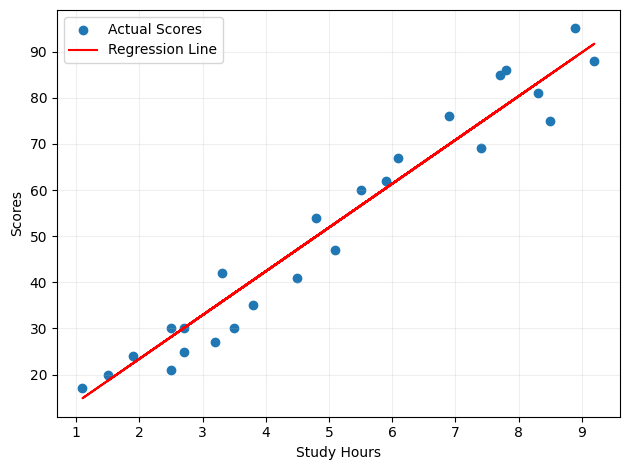

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Programmatically creating the missing score.csv with mock data
synthetic_data = {
    'Hours': [2.5, 5.1, 3.2, 8.5, 3.5, 1.5, 9.2, 5.5, 8.3, 2.7, 7.7, 5.9, 4.5, 3.3, 1.1, 8.9, 2.5, 1.9, 6.1, 7.4, 2.7, 4.8, 3.8, 6.9, 7.8],
    'Scores': [21, 47, 27, 75, 30, 20, 88, 60, 81, 25, 85, 62, 41, 42, 17, 95, 30, 24, 67, 69, 30, 54, 35, 76, 86]
}
pd.DataFrame(synthetic_data).to_csv("score.csv", index=False)

df = pd.read_csv("score.csv")

X = df[["Hours"]].values
y = df["Scores"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=14000
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Student Performance Prediction")
print("------------------------------")
print("Coefficient:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

print("\nActual vs Predicted:")
for actual, predicted in zip(y_test, y_pred):
    print("Actual:", actual, "Predicted:", round(predicted, 2))

plt.scatter(X, y, label="Actual Scores")
plt.plot(X, model.predict(X), color="red", label="Regression Line")

plt.xlabel("Study Hours")
plt.ylabel("Scores")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

Model Accuracy: 100.0 %
Enter study hours: 5
Predicted Result: Pass
Probability of passing: 58.66 %


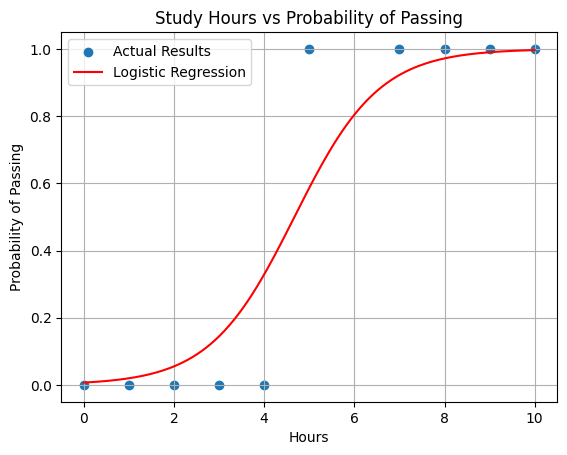

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = np.array([1, 2, 3, 0, 4, 5, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

hours = float(input("Enter study hours: "))
prediction = model.predict([[hours]])
probability = model.predict_proba([[hours]])

if prediction[0] == 1:
    print("Predicted Result: Pass")
else:
    print("Predicted Result: Fail")

print("Probability of passing:", round(probability[0][1] * 100, 2), "%")

plt.scatter(X, y, label="Actual Results")
plt.plot(
    np.linspace(0, 10, 200).reshape(-1, 1),
    model.predict_proba(
        np.linspace(0, 10, 200).reshape(-1, 1)
    )[:, 1],
    label="Logistic Regression",
    color="red"
)

plt.xlabel("Hours")
plt.ylabel("Probability of Passing")
plt.title("Study Hours vs Probability of Passing")
plt.legend()
plt.grid(True)
plt.show()